Dataset shape: (126865, 62)
Using 'daily_energy_met_y' as the target variable for electricity prediction.
Sampling 20,000 rows for faster training...
Training Random Forest Regressor...
Random Forest R^2 Score on Test: 0.9096718331500422
Training Gradient Boosting Regressor...
Gradient Boosting R^2 Score on Test: 0.9446308844158631


/tmp/ipykernel_3366/3049778935.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_importances[rf_indices], y=X.columns[rf_indices], palette='viridis')
/tmp/ipykernel_3366/3049778935.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=gb_importances[gb_indices], y=X.columns[gb_indices], palette='magma')


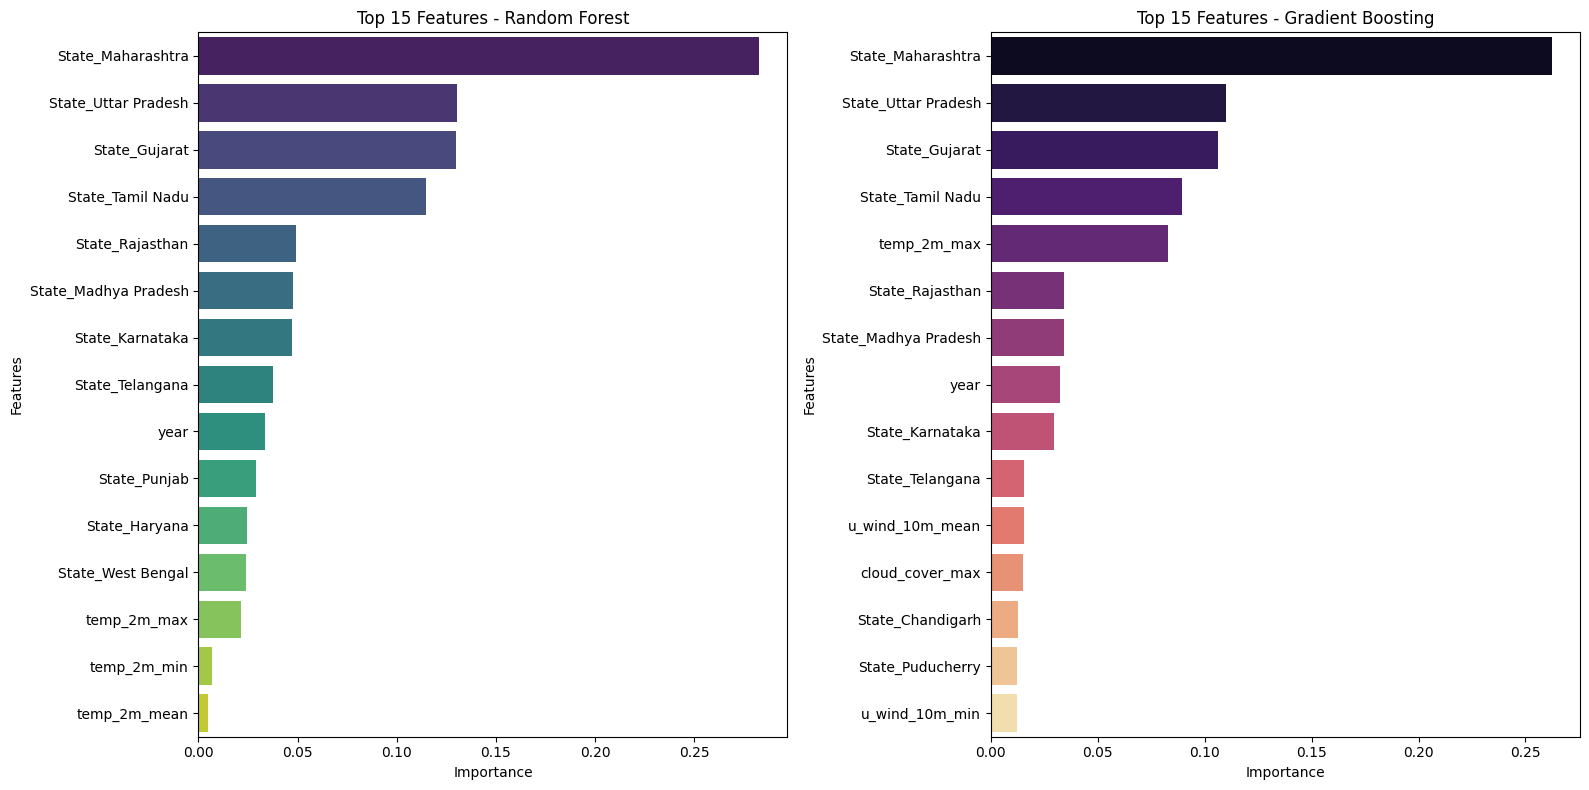

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 1. Load the dataset
df = pd.read_csv('/content/main_data_electricity.csv')
print("Dataset shape:", df.shape)

# Defining the correct target variable
target_col = 'daily_energy_met_y'
print(f"Using '{target_col}' as the target variable for electricity prediction.")

# Identify columns to drop (other potential targets or non-predictive variables to avoid target leakage)
cols_to_drop = [target_col, 'corr_daily_energy_met_y', 'corr_peak_met_y', 'peak_met_y', 'peak_unmet_y']

# Extract features (X) and target (y)
X = df.drop(columns=[col for col in cols_to_drop if col in df.columns])
y = df[target_col]

# Handle missing values if any
X = X.fillna(X.median())
y = y.fillna(y.median())

# Split the dataset (using a subset if the dataset is large for faster training in this environment)
# 126k rows with 60 features can take some time; we will train on a 20% sample for fast visualization
if len(df) > 30000:
    print("Sampling 20,000 rows for faster training...")
    X_sample, _, y_sample, _ = train_test_split(X, y, train_size=20000, random_state=42)
else:
    X_sample, y_sample = X, y

X_train, X_test, y_train, y_test = train_test_split(X_sample, y_sample, test_size=0.2, random_state=42)

# 3. Train models
print("Training Random Forest Regressor...")
rf_model = RandomForestRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
print("Random Forest R^2 Score on Test:", rf_model.score(X_test, y_test))

print("Training Gradient Boosting Regressor...")
gb_model = GradientBoostingRegressor(n_estimators=50, max_depth=6, random_state=42)
gb_model.fit(X_train, y_train)
print("Gradient Boosting R^2 Score on Test:", gb_model.score(X_test, y_test))

# 4. Visualize top 15 Feature Importances
rf_importances = rf_model.feature_importances_
gb_importances = gb_model.feature_importances_

rf_indices = np.argsort(rf_importances)[::-1][:15]
gb_indices = np.argsort(gb_importances)[::-1][:15]

plt.figure(figsize=(16, 8))

# Random Forest Plot
plt.subplot(1, 2, 1)
sns.barplot(x=rf_importances[rf_indices], y=X.columns[rf_indices], palette='viridis')
plt.title('Top 15 Features - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Features')

# Gradient Boosting Plot
plt.subplot(1, 2, 2)
sns.barplot(x=gb_importances[gb_indices], y=X.columns[gb_indices], palette='magma')
plt.title('Top 15 Features - Gradient Boosting')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [4]:
import joblib
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
import pandas as pd

# Calculate predictions
rf_preds = rf_model.predict(X_test)
gb_preds = gb_model.predict(X_test)

# Evaluate Random Forest
rf_metrics = {
    'Model': 'Random Forest',
    'R2': r2_score(y_test, rf_preds),
    'MAE': mean_absolute_error(y_test, rf_preds),
    'RMSE': root_mean_squared_error(y_test, rf_preds)
}

# Evaluate Gradient Boosting
gb_metrics = {
    'Model': 'Gradient Boosting',
    'R2': r2_score(y_test, gb_preds),
    'MAE': mean_absolute_error(y_test, gb_preds),
    'RMSE': root_mean_squared_error(y_test, gb_preds)
}

# Compare metrics in a DataFrame
metrics_df = pd.DataFrame([rf_metrics, gb_metrics])
display(metrics_df)

# Choose the best model based on R2 score
best_model_row = metrics_df.loc[metrics_df['R2'].idxmax()]
best_model_name = best_model_row['Model']

if best_model_name == 'Random Forest':
    best_model = rf_model
else:
    best_model = gb_model

print(f"\nSaving the best model ({best_model_name}) to a .pkl file...")
model_filename = 'best_electricity_model.pkl'
joblib.dump(best_model, model_filename)
print(f"Model saved successfully as '{model_filename}'!")

,Model,R2,MAE,RMSE
0,Random Forest,0.909672,26.549918,36.807879
1,Gradient Boosting,0.944631,21.352705,28.817943



Saving the best model (Gradient Boosting) to a .pkl file...
Model saved successfully as 'best_electricity_model.pkl'!


In [6]:
!pip install -q statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.arima.model import ARIMA

# --- 1. Train Additional Machine Learning Models ---
print("Training Ridge Regression...")
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_preds = ridge_model.predict(X_test)

print("Training Extra Trees Regressor...")
et_model = ExtraTreesRegressor(n_estimators=50, max_depth=12, random_state=42, n_jobs=-1)
et_model.fit(X_train, y_train)
et_preds = et_model.predict(X_test)

# --- 2. Implement a Time Series Baseline (ARIMA) ---
# For time-series, we assume the dataset contains a sequential chronological order.
# We will group by the sequential indices or a time feature if available to build an ARIMA baseline.
print("Fitting ARIMA baseline model...")
target_series = y_sample.values
train_size = int(len(target_series) * 0.8)
ts_train, ts_test = target_series[:train_size], target_series[train_size:]

# Fit simple ARIMA(1, 1, 1) model
try:
    arima_model = ARIMA(ts_train, order=(1, 1, 1))
    arima_result = arima_model.fit()
    # Forecast next steps
    arima_preds = arima_result.forecast(steps=len(ts_test))
    ts_mae = mean_absolute_error(ts_test, arima_preds)
    ts_rmse = root_mean_squared_error(ts_test, arima_preds)
    ts_r2 = r2_score(ts_test, arima_preds)
except Exception as e:
    print("ARIMA failed to converge, using naive forecast baseline:", e)
    arima_preds = np.full(shape=len(ts_test), fill_value=ts_train[-1])
    ts_mae = mean_absolute_error(ts_test, arima_preds)
    ts_rmse = root_mean_squared_error(ts_test, arima_preds)
    ts_r2 = r2_score(ts_test, arima_preds)

# --- 3. Consolidate and Compare All Scores ---
additional_metrics = [
    {
        'Model': 'Ridge Regression',
        'R2': r2_score(y_test, ridge_preds),
        'MAE': mean_absolute_error(y_test, ridge_preds),
        'RMSE': root_mean_squared_error(y_test, ridge_preds)
    },
    {
        'Model': 'Extra Trees',
        'R2': r2_score(y_test, et_preds),
        'MAE': mean_absolute_error(y_test, et_preds),
        'RMSE': root_mean_squared_error(y_test, et_preds)
    },
    {
        'Model': 'ARIMA Time Series Baseline',
        'R2': ts_r2,
        'MAE': ts_mae,
        'RMSE': ts_rmse
    }
]

all_metrics_df = pd.concat([
    metrics_df,
    pd.DataFrame(additional_metrics)
], ignore_index=True)

print("\n--- Updated Model Comparison (Including Time Series) ---")
display(all_metrics_df)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 121.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 15.4 MB/s eta 0:00:00
Training Ridge Regression...
Training Extra Trees Regressor...
Fitting ARIMA baseline model...

--- Updated Model Comparison (Including Time Series) ---


,Model,R2,MAE,RMSE
0,Random Forest,0.909672,26.549918,36.807879
1,Gradient Boosting,0.944631,21.352705,28.817943
2,Ridge Regression,0.946807,19.037192,28.245960
3,Extra Trees,0.910072,24.952475,36.726177
4,ARIMA Time Series Baseline,-0.000621,97.284195,120.441801


In [7]:
import joblib
from google.colab import files

# Find the overall best model from our updated performance table (excluding the time-series model)
ml_metrics_df = all_metrics_df[all_metrics_df['Model'] != 'ARIMA Time Series Baseline']
best_ml_row = ml_metrics_df.loc[ml_metrics_df['R2'].idxmax()]
best_ml_name = best_ml_row['Model']
best_ml_score = best_ml_row['R2']

# Map name to its actual model object
model_mapping = {
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model,
    'Ridge Regression': ridge_model,
    'Extra Trees': et_model
}

export_model = model_mapping[best_ml_name]
export_filename = 'overall_best_electricity_model.pkl'

# Export the model
joblib.dump(export_model, export_filename)
print(f"Overall Best Model: {best_ml_name} (R^2 Score: {best_ml_score:.5f})")
print(f"Successfully exported model to '{export_filename}'.")

# Trigger browser download of the exported file
print("Triggering model download...")
files.download(export_filename)


Overall Best Model: Ridge Regression (R^2 Score: 0.94681)
Successfully exported model to 'overall_best_electricity_model.pkl'.
Triggering model download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>